# Matrices
$$
A_{m \times n} = 
\begin{bmatrix} 
a_{11} & a_{12} & a_{13} & \dots & a_{1n} \\
a_{21} & a_{22} & a_{13} & \dots & a_{1n} \\
\dots & \dots & \dots & \dots & \dots\\
a_{m1} & \dots & \dots & \dots & a_{mn}
\end{bmatrix}
$$

> $m$ -> Number of rows ; $n$ -> Number of columns 

Most high school student might see matrix as a block of numbers. But one of the most beautiful feature of matrix is, you can understand it from different "angles"(rows, columns, smaller block, ...), is all about `Linear Combination`.
$$
M_{3 \times 3} = 
\begin{bmatrix} 
1 & 2 & 3\\
4 & 5 & 6\\
7 & 8 & 9\\
\end{bmatrix}
$$

The matrix also tell you the details of the space
- If I am a **column** guy, I would say Matrix M is a space that contain linear combination of vectors (1, 4, 7), (2, 5, 8), (3, 6, 9)
- If I am a **row** guy, I would say Matrix M is a space that contain linear combination of vectors (1, 2, 3), (4, 5, 6), (7, 8, 9)

So what meant by `Linear Combination`?

$\vec{v_o}$ = $c_1\vec{v_1} + c_2\vec{v_2}$, $c$ can be any number(include negative). In this case, we can say $\vec{v_o}$ is linear combination of ${\vec{v_1}}$ and ${\vec{v_2}}$ OR $\vec{v_o}$ is depend on ${\vec{v_1}}$ and ${\vec{v_2}}$.

- Is (1, 1, 1) in column space of M? YES
- Is (8, 10, 12) in the row space of M? YES
> Later when we talk about the matrix multiplication we also can see the `Linear Combination`

---

## Different types of matrix
- **Square Matrix**: number of columns equal to number of rows matrix M is an example
- **Diagonal Matrix**: Only diagonal elements is not 0
  $$
    D_{3 \times 3} = \begin{bmatrix} 2&0&0 \\ 0&-8&0 \\ 0&0&10\end{bmatrix}
  $$
- **Identity Matrix**: Special diagonal matrix -> all diagonal elements are 1
  $$
    I_{3 \times 3} = \begin{bmatrix} 1&0&0 \\ 0&1&0 \\ 0&0&1\end{bmatrix}
  $$

## Basic Matrix Operations
### Transpose
Swap the columns with rows.
$$
\begin{align}
M_1 &= \begin{bmatrix} 2&4&6 \\ 1&-8&1 \\ 1&3&5\end{bmatrix} \\
M_1^T &= \begin{bmatrix} 2&4&6 \\ 1&-8&1 \\ 1&3&5\end{bmatrix}^T \\ 
&= \begin{bmatrix} 2&1&1 \\ 4&-8&3 \\ 6&1&5\end{bmatrix}
\end{align}
$$


- Symmetric Matrix : $M^T = M$
- Skew-Symmetric Matrix : $M^T = -M$

In [1]:
import numpy as np

In [4]:
M =np.array([
    [2, 4, 6],
    [1, -8, 1],
    [1, 3, 5]
])

print(f"M shape:{M.shape}")

M.T  # Transpose

M shape:(3, 3)


array([[ 2,  1,  1],
       [ 4, -8,  3],
       [ 6,  1,  5]])

In [12]:
from numpy.testing import assert_array_equal
def isSymmetric(matrix:np.ndarray)->bool:
    try:
        assert_array_equal(matrix, matrix.T)
    except Exception:
        return False
    return True

def isSkewSymmetric(matrix: np.ndarray) -> bool:
    try:
        assert_array_equal(matrix, -1*matrix.T)
    except Exception:
        return False
    return True

In [ ]:
I = np.array([
    [1, 0, 0], 
    [0, 1, 0], 
    [0, 0, 1]
])

print(f"Symmetric:{isSymmetric(I)} Skew-Symmetric:{isSkewSymmetric(I)}")

Symmetric:True Skew-Symmetric:True


## Matrix Addition / Subtraction
Matrices must have the same 'shape'($m \times n$) to perform addition or subtraction.
It has followings properties:
- `Commutative`: $A + B = B + A$ 
- `Associative`: $(A + B) + C = A + (B +C)$

Example:
$$
\begin{align}
\begin{bmatrix} 1& 1 \\ 1& 1 \end{bmatrix} + \begin{bmatrix} 1& -1 \\ 5& 9 \end{bmatrix} &=
\begin{bmatrix} 1+1& 1-1 \\ 1+5& 1+9 \end{bmatrix} \\
&= \begin{bmatrix} 2& 0 \\ 6& 10 \end{bmatrix}
\end{align}
$$

In [16]:
A = np.array([
    [1, 1],
    [1, 1]
])
B = np.array([
    [1, -1], 
    [5, 9]
])
A + B

array([[ 2,  0],
       [ 6, 10]])

## Trace
Summation of all diagonal elements of the square matrix, denoted by $tr(M)$

Given a $m \times m$ square matrix $M_1$:
$$
\begin{bmatrix}
a_{11} & \dots & a_{1m} \\
\dots & \dots & \dots \\
a_{m1} & \dots & a_{mm}
\end{bmatrix}
$$

$$
tr(M_1) = \sum_{i=1}^m a_{ii}
$$

Example:
$$
tr(
\begin{bmatrix}
1 & 2 & 3 \\
4 & 5 & 6 \\
7 & 8 & 9
\end{bmatrix}
) = 1 + 5 + 9 = 15
$$

In [17]:
M1 = np.array([
    [1, 2, 3],
    [4, 5, 6],
    [7, 8, 9]
])
M1.trace()

np.int64(15)

## Scalar Multiplication
All elements times the multiplier.(like broadcasting a number to every one)

Example:
$$
10 \begin{bmatrix} 1& 2 \\ 3& 4 \end{bmatrix} = \begin{bmatrix} 1 \times 10 & 2 \times 10\\ 3 \times 10& 4 \times 10\end{bmatrix}
$$

In [18]:
M1 = np.array([
    [1,2], [3, 4]
])
10 * M1

array([[10, 20],
       [30, 40]])

## Matrix Multiplication
Before we looking at the general formula of matrix multiplication, lets us explore the beauty of `Linear Combination` first!
$$
A = \begin{bmatrix} a_{11} & a_{12} & a_{13} \\ a_{21} & a_{22} & a_{23} \\ a_{31} & a_{32} & a_{33} \\ \end{bmatrix} \, 
B = \begin{bmatrix} b_{11} & b_{12} & b_{13} \\ b_{21} & b_{22} & b_{23} \\ b_{31} & b_{32} & b_{33} \\ \end{bmatrix} \\
$$

There are 2 ways to looking at $AB= M$

$$
\begin{bmatrix} 1 & 2 & 3 \\ 4 & 5 & 6 \\ 7 & 8 & 9 \\ \end{bmatrix}
\begin{bmatrix} 1 & 0 & 0 \\ 0 & 0 & 1 \\ 1 & 1 & -1 \\ \end{bmatrix} =
\begin{bmatrix} 4 & 3 & -1 \\ 10 & 6 & -1 \\ 16 & 9 & -1 \\ \end{bmatrix}
$$

### Column View
B is taking combination of column vectors in A, therefore M depend on column vectors in A (M lie within column space of A)

- $\begin{bmatrix}4 \\10 \\16 \end{bmatrix} = 1\begin{bmatrix}1 \\4 \\7 \end{bmatrix} + 1\begin{bmatrix}3 \\6 \\9 \end{bmatrix}$
- $2^{nd}$ Column of M is the third column of A, because b is taking $\begin{bmatrix}0 \\0 \\1 \end{bmatrix}$
- $\begin{bmatrix}-1 \\-1 \\-1 \end{bmatrix} = 1\begin{bmatrix}2 \\5 \\8 \end{bmatrix} - 1\begin{bmatrix}3 \\6 \\9 \end{bmatrix}$

### Row View
A is taking combination of row vectors in B, therefore M is also depend on row vectors in B (M lie within row space of A)
- $\begin{bmatrix} 4 & 3 & -1\end{bmatrix} = 1\begin{bmatrix} 1 & 0 & 0\end{bmatrix} + 2\begin{bmatrix} 0 & 0 & 1\end{bmatrix} + 3\begin{bmatrix} 1 & 1 & -1\end{bmatrix}$
- $\begin{bmatrix} 10 & 6 & -1\end{bmatrix} = 4\begin{bmatrix} 1 & 0 & 0\end{bmatrix} + 5\begin{bmatrix} 0 & 0 & 1\end{bmatrix} + 6\begin{bmatrix} 1 & 1 & -1\end{bmatrix}$
- $\begin{bmatrix} 16 & 9 & -1\end{bmatrix} = 7\begin{bmatrix} 1 & 0 & 0\end{bmatrix} + 8\begin{bmatrix} 0 & 0 & 1\end{bmatrix} + 9\begin{bmatrix} 1 & 1 & -1\end{bmatrix}$

> Do you get the idea? Are you able to explain why $AI=A$?

### Operator/Transformation View
We also can interpret $AB=M$ as 
- matrix A operate on column vectors of B, therefore column vectors of M is transformed vectors of B.   
- matrix B operate on row vectors of A, therefore row vectors of M in transformed vectors of A.

> So there is condition for matrices to perform multiplication $A_{m \times n} B_{n \times p}$ the product will be $M_{m \times p}$.
> 
> If number of columns of A not match with number of rows of B, you are not able to take the combination

### Why $AB \neq BA$ ?
Columns views:
- In $AB$ => B is combining column vectors of A, the final product is depend on column vectors of A (not B)
- In $BA$ => A is combining column vectors of B, the final product is depend on column vectors of B (not A)

Rows views:
- In $AB$ => A is combining row vectors of B, the final product is depend on row vectors of B (not A)
- In $BA$ => B is combining row vectors of A, the final product is depend on row vectors of A (not B)
> Therefore, $AB$ and $BA$ are different matrices, and we said that matrix multiplication is `not commutative`.

Try to use same concept to understand $(AB)^T = B^TA^T$. (Take out a piece of paper and take your time to create your matrices to try it out!)

### General Formula of Matrix Multiplication
![Matrix Multiplication](../../Assets/images/MatrixMult.png)
$$
\begin{align}
&AB \\ &=
\begin{bmatrix}
a_{11} & a_{12} & a_{13} \\
a_{21} & a_{22} & a_{23} \\
a_{31} & a_{32} & a_{33}
\end{bmatrix}
\begin{bmatrix}
b_{11} & b_{12} & b_{13} \\
b_{21} & b_{22} & b_{23} \\
b_{31} & b_{32} & b_{33}
\end{bmatrix}
\\ &=
\begin{bmatrix}
a_{11}b_{11} + a_{12}b_{21} + a_{13}b_{31} & a_{11}b_{12} + a_{12}b_{22} + a_{13}b_{32} & a_{11}b_{13} + a_{12}b_{23} + a_{13}b_{33}\\
a_{21}b_{11} + a_{22}b_{21} + a_{23}b_{31} & a_{21}b_{12} + a_{22}b_{22} + a_{23}b_{32} & a_{21}b_{13} + a_{22}b_{23} + a_{23}b_{33}\\
a_{31}b_{11} + a_{32}b_{21} + a_{33}b_{31} & a_{31}b_{12} + a_{32}b_{22} + a_{33}b_{32} & a_{31}b_{13} + a_{32}b_{23} + a_{33}b_{33}\\
\end{bmatrix}
\end{align}
$$


In [ ]:
A = np.array([
    [1, 2, 3],
    [4, 5, 6],
    [7, 8, 9]
])
B = np.array([[1, 0, 0], [0, 0, 1], [1,1, -1]])
M = A@B
M.T

array([[ 4, 10, 16],
       [ 3,  6,  9],
       [-1, -1, -1]])

## Inverse Matrix  $A^{-1}$
If a matrix is invertible, it is `non-singular`, or else it is a `singular` matrix.

**Why $AA^{-1} = A^{-1}A=I$ must be true?**
1. $AI=A$ ; $IA=A$ -> $I$ can also become operator who do nothing
2. Since matrix multiplication is consider as taking combination, can we combine the operators? YES!
   - $ABCM$, $ABC$ operate $M$ so we can combine $ABC$
   - If we define $O = ABC$
   - We then can simplify $ABCM$ to $OM$ ($O$ operate $M$)
3. Back to our case, now $A$ is operator, $A^{-1}$ represent the inverse operation of $A$
   - If A operator that rotate vector 30 degree clockwise
   - $A^{-1}$ is inverse of A means it will rotate vectors 30 degree anticlockwise
4. If you rotate a vector 30 degree clockwise, then rotate it 30 degree anticlockwise, What happen to the final vector? (exactly same with vector at beginning!) 
5. Now what if rotate anticlockwise first, then rotate clockwise with same degree. Is there any difference between final vector and initial vector? (NO difference they are same)
6. So you are doing nothing
7. Hence, $AA^{-1} = I$ must be true

> $O=ABC$ , $O^{-1}=C^{-1}B^{-1}A^{-1}$

### General formula of inverse matrix
$$
A^{-1} = \frac{1}{\det A} A_{adj}
$$
If $\det A = 0$, $A$ must be singular (not invertible)
You may refer to the following resources:
- Determinant: [KhanAcademy](https://www.google.com/url?sa=t&source=web&rct=j&opi=89978449&url=https://www.khanacademy.org/math/multivariable-calculus/thinking-about-multivariable-function/x786f2022:vectors-and-matrices/a/determinants-mvc&ved=2ahUKEwjSwoW2vuaVAxXOe2wGHdQMHk8QFnoECCwQAQ&usg=AOvVaw0SpxbapPCYRU1c0u57EEKV)
- Adjoint: [KhanAcademy](https://youtu.be/wtSjH8YeJs8?si=d8FsNdmB6KSmuBbL)

((<Figure size 800x800 with 2 Axes>, <Axes: >),
 <Axes3D: xlabel='X Axis', ylabel='Y Axis', zlabel='Z Axis'>)

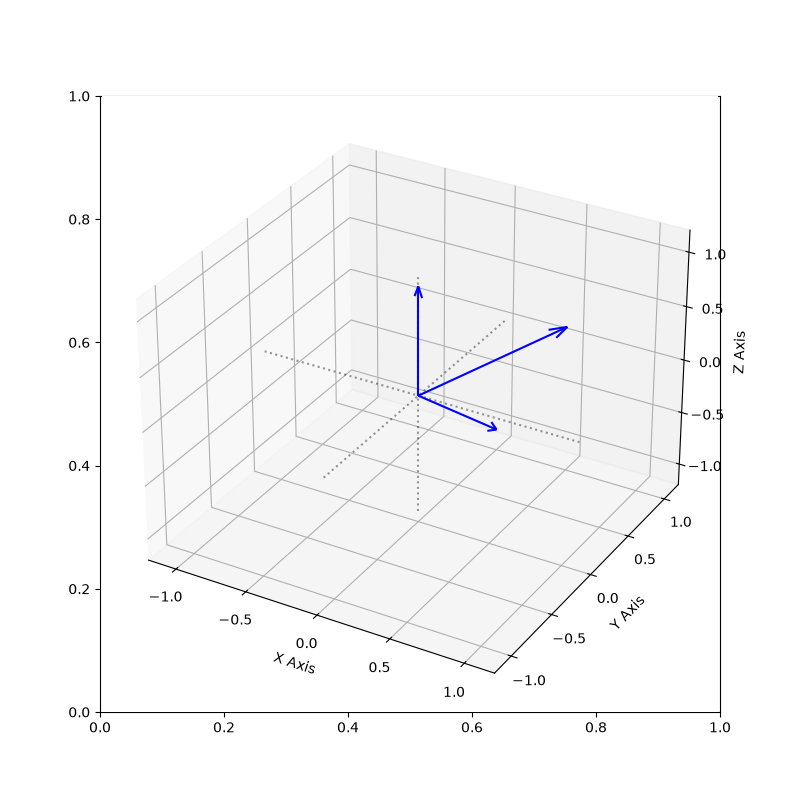

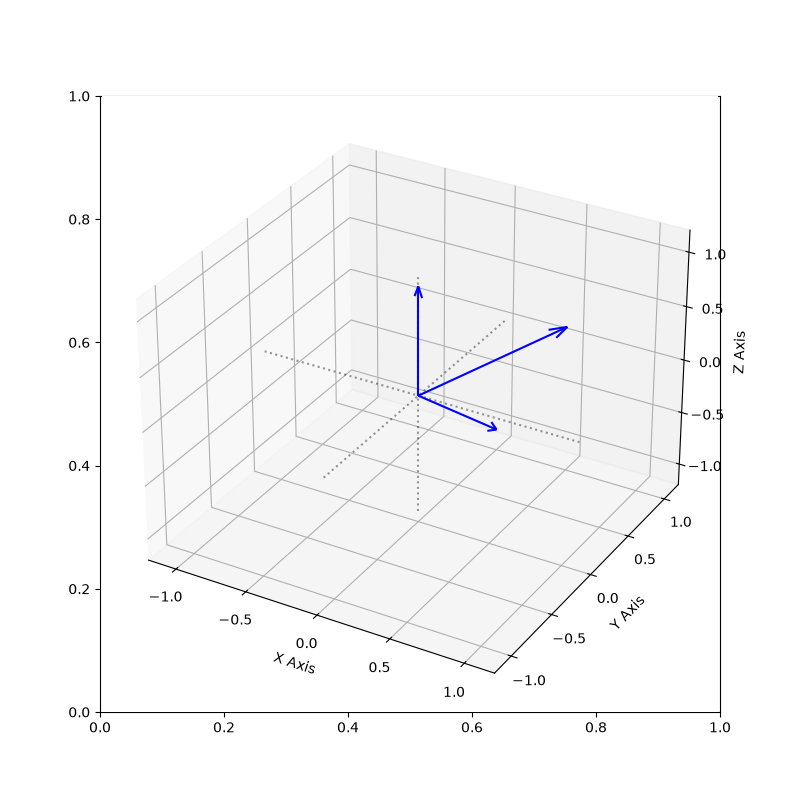

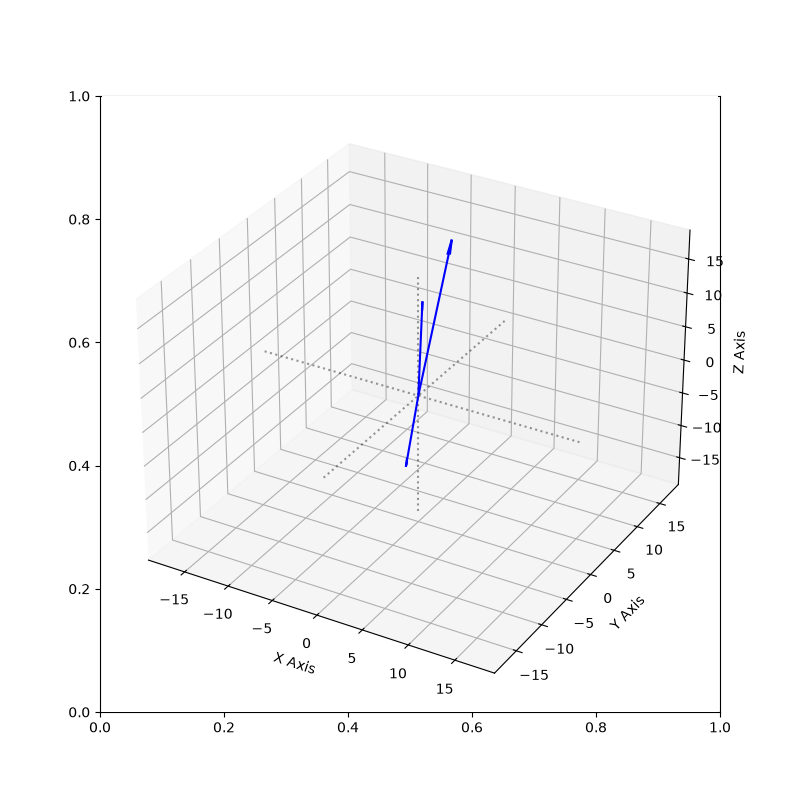

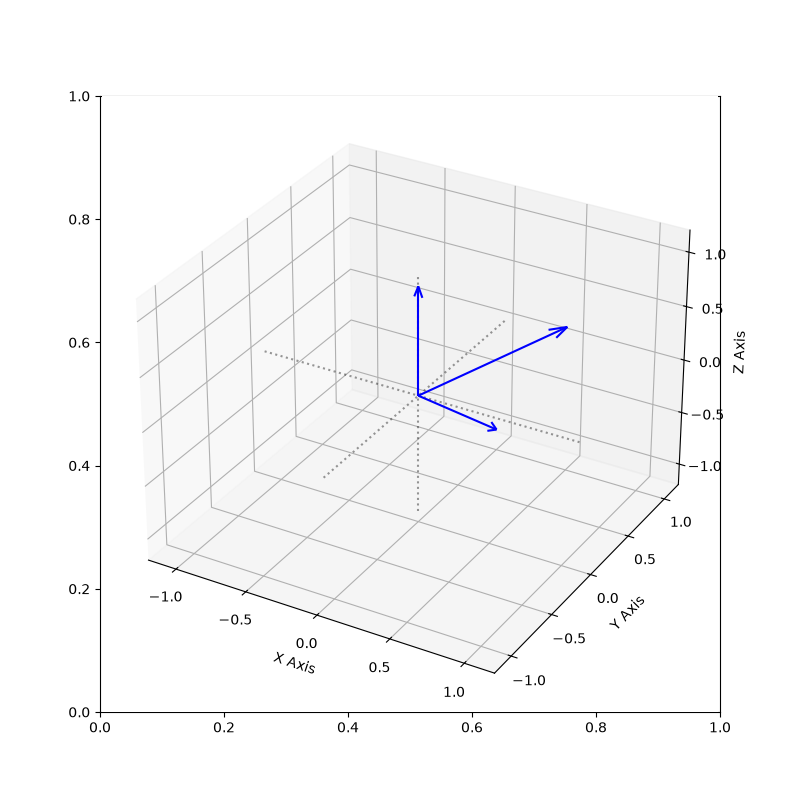

In [2]:
%matplotlib ipympl
from bridge_my_qc.helpers.plot import plot_cartesian_3d

A = np.array([
    [1, 2, -3], 
    [4, -5, 6],
    [7, 8, 9]]
)
B = np.array([
    [1, 0, 0],
    [0, 0, 1],
    [1, 1, -1]
])
I = np.array([
    [1, 0, 0],
    [0, 1, 0],
    [0, 0, 1]
])
M1 = A @ B
A_inverse = np.linalg.inv(A)
M2 = A_inverse@M1

def get_column_vectors(matrix):
    return [matrix[:, i] for i in range(matrix.shape[1])]

def get_row_vectors(matrix):
    return [matrix[i] for i in range(matrix.shape[0])]

def isSingular(matrix):
    det = np.linalg.det(matrix)
    print(f"Determinant is {det}")
    return not bool(det)

transformed_vectors = get_row_vectors(B)
plot_cartesian_3d(get_column_vectors(B), "vector")
plot_cartesian_3d(get_column_vectors(I@B), "vector")
plot_cartesian_3d(get_column_vectors(M1), "vector")
plot_cartesian_3d(get_column_vectors(M2), "vector")